<img src="logo.jpg" alt="Logo" width="500"/>

# Comp4388: Machine Learning
**2025/2026**


### Name: Rawan Yahya  &emsp;  Number: 1221239

### Name: Hanan Ibraheem Naji  &emsp;  Number: 1220651

### Section Number: #1

---





# ***convolutional Neaural Network (CNN) to Pneumonia Detection using Chest X-ray Images***  
### Prepared By :Hanan Naji and Rawan Yahya  

## 0.1 Abstract :-
Chest X-rays are used for detecting the Pneumonia infection and to locate the infected area in the lungs. So, To detect the the pneumonia radiologist have to observe the chest xray and he/she has to update the doctor correctly.  


 This project focuses on the development and training of a Convolutional Neural Network ,to classify Chest X-ray images into Pneumonia and Normal.  


Deep Learning models which are trained correctly by using good datasets (The dataset consists of three folder: test, validation, and training, with each folder containing two subfolder one for images of chests diagnosed with pneumonia and the other for images of normal chests.)can be helpful for doctors. To train the model for detecting whether the person has pneumonia or not, A Convolutional Neural Network(CNN) is used. The CNN can train the images of chest xrays and then it can predict with high accuracy.  


---


# 0.2 Project introduction:(jupytor and tools that used)

  
### Tools
* Jupyter Notebook:An interactive web-based environment that allows for writing Python code, displaying results, creating visualizations, and including explanations all in one place. It is widely used for data science, machine learning, and deep learning projects.  

* Python:-   The programming language used to implement the machine learning and deep learning algorithms.   




 
 ---
 


### Import Libraries :-
* TensorFlow : used to build and train Convolutional Neural Networks for image classification tasks.

* Numpy : Used for multidimensional arrays

* Matplotlib : Used to visualize data with graphs.
* Keras : It is the interface for Neural Networks and Tensorflow.
* sklearn metrics :Used to evaluate model performance with metrics like accuracy, precision, recall, F1-score, and confusion matrix. 

In [17]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras import regularizers
from tensorflow.keras.layers import Conv2D, MaxPooling2D, AveragePooling2D, Flatten, Dense, Dropout
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

# 2: Preparing and Augmentation  the data
# 2.1: Creating variables with paths to each folder of the datasets
*  we prepared the training, validation, and test sets for the model. We start by defining the paths for the images for each set . 




 

In [18]:
# pathes for the file 
train_destination = "Chest X-Rays.v4i.folder/train/"  
val_destination = "Chest X-Rays.v4i.folder/valid/"  
test_destination = "Chest X-Rays.v4i.folder/test/"  

# 2.2 : Plotting count plots for each of the datasets to get some insight into how many instances of each of the target variable classes are there.


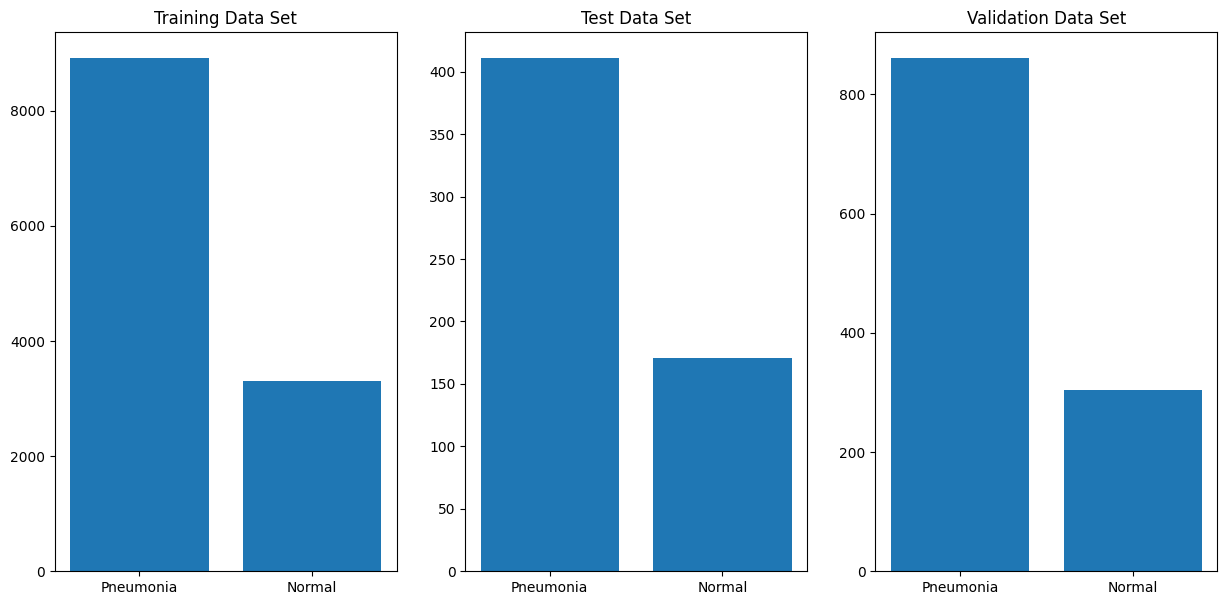

In [5]:

import os 
f = plt.figure(figsize=(15,7))

plt.subplot(1, 3, 1)
plt.bar(x=["Pneumonia", "Normal"], height=[
    len(os.listdir(train_destination + "/PNEUMONIA")),
    len(os.listdir(train_destination + "/NORMAL"))
])
plt.title("Training Data Set")

plt.subplot(1, 3, 2)
plt.bar(x=["Pneumonia", "Normal"], height=[
    len(os.listdir(test_destination + "/PNEUMONIA")),
    len(os.listdir(test_destination + "/NORMAL"))
])
plt.title("Test Data Set")

plt.subplot(1, 3, 3)
plt.bar(x=["Pneumonia", "Normal"], height=[
    len(os.listdir(val_destination + "/PNEUMONIA")),
    len(os.listdir(val_destination + "/NORMAL"))
])
plt.title("Validation Data Set")

plt.show()


From the chart,  the Pneumonia class has a larger number of images compared to the Normal class in all datasets (training, validation, and testing). This indicates an imbalance between the classes, with Pneumonia dominating the dataset.   




To reduce the class imbalance, we applied data augmentation during training. This included rotation, zoom, and horizontal flipping, which create more variety in the training images and help the model learn better, especially for the Normal class that has fewer images.

--- 
# 2.3 :Data Augmentation:   

* Data Augmentation for Training:  We apply several transformations to the training images to increase diversity and prevent overfitting. These transformations include:
   * Rotation.
  * Zoom.
  * Horizontal Flip.

* Normalization:  All images are rescaled to a range of [0, 1] to standardize the pixel values.

* Image size : consistent size of  120x120  to ensure that all images fit into the model.

* Batch Size The training data is processed in batches of 16 images at a time.

* ImageDataGenerator: to load and process the images in batches for training, validation, and testing.

<p style="text-align:center; font-weight:bold;">
[  Data Augmentation ]
</p>

<img src="image.png" width="900" height="400"/>


Image data augmentation is a technique that is used to artificially expand the dataset. 



Image augmentation parameters that are generally used to increase the data sample are zooming in and out, shear, rotation and so on. Usage of these parameters results in the generation of new images during the training of the Deep Learning model. Image samples generated using image augmentation, in general results in the increase of existing data sample set by nearly 3x to 4x times.    




In [19]:
train_img_generator = ImageDataGenerator(rescale=1./255,  #normalize img to [0,1]
                                    rotation_range=25,
                                      zoom_range=0.1,
                                        horizontal_flip=True)

val_img_generator= ImageDataGenerator(rescale=1./255,  #normalize img to [0,1]
                                    rotation_range=25,
                                      zoom_range=0.1,
                                        horizontal_flip=True)
test_img_generator = ImageDataGenerator(rescale=1./255)

IMG_SIZE = (120, 120)
BATCH_SIZE = 16

#load the train/valid/test data with spesific setting
train_img_loader = train_img_generator.flow_from_directory(
   train_destination ,
                                               target_size=IMG_SIZE,
                                                 batch_size=BATCH_SIZE,
                                                   class_mode='binary')

val_img_loader = val_img_generator.flow_from_directory(val_destination,
                                           target_size=IMG_SIZE,
                                             batch_size=BATCH_SIZE,
                                               class_mode='binary')

test_img_loader = test_img_generator.flow_from_directory(test_destination , 
                                            target_size=IMG_SIZE,
                                              batch_size=1, 
                                              class_mode='binary',
                                                shuffle=False)


Found 12229 images belonging to 2 classes.
Found 1165 images belonging to 2 classes.
Found 582 images belonging to 2 classes.


---
# 3: Displaying  Images from the dataset file 

we display 6 sample images from the train, Validation, Test . 
This helps verify that the images have been read correctly and that we are successfully accessing the files from each folder(normal and pneumonia).
 to ensure that the data loading process works correctly and that we are properly accessing the images for training, validation, and testing.


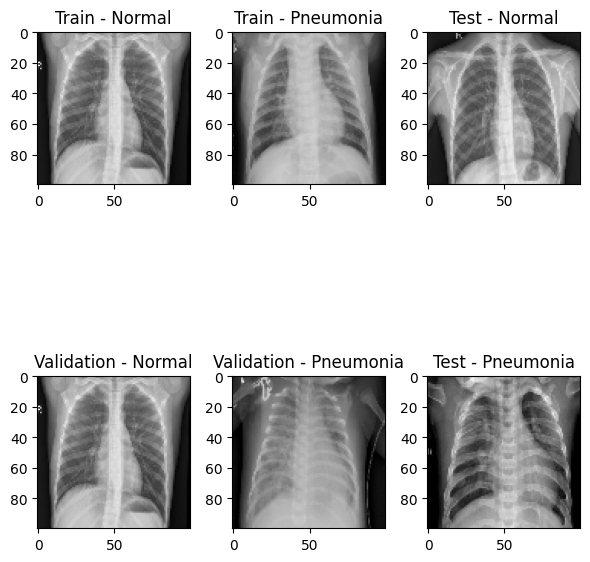

In [12]:
from tensorflow.keras.preprocessing import image

def display_sample_image_from_directory(directory_path, label, title, ax):
    image_files = os.listdir(directory_path)
    image_path = os.path.join(directory_path, image_files[0]) 

    img = image.load_img(image_path, target_size=IMG_SIZE)
    img_array = image.img_to_array(img) / 255.0  

    ax.imshow(img_array)
    
    ax.set_title(f'{title} - {label}')

fig, axes = plt.subplots(2,3, figsize=(6, 8))

IMG_SIZE = (100, 100)

train_normal_path = os.path.join(train_destination, "NORMAL")
train_pneumonia_path = os.path.join(train_destination, "PNEUMONIA")
val_normal_path = os.path.join(train_destination, "NORMAL")
val_pneumonia_path = os.path.join(val_destination, "PNEUMONIA")
test_normal_path = os.path.join(test_destination, "NORMAL")
test_pneumonia_path = os.path.join(test_destination, "PNEUMONIA")

display_sample_image_from_directory(train_normal_path, 'Normal', 'Train', axes[0, 0])
display_sample_image_from_directory(train_pneumonia_path, 'Pneumonia', 'Train', axes[0, 1])
display_sample_image_from_directory(val_normal_path, 'Normal', 'Validation', axes[1, 0])
display_sample_image_from_directory(val_pneumonia_path, 'Pneumonia', 'Validation', axes[1, 1])
display_sample_image_from_directory(test_normal_path, 'Normal', 'Test', axes[0, 2])
display_sample_image_from_directory(test_pneumonia_path, 'Pneumonia', 'Test', axes[1, 2])

plt.tight_layout()
plt.show()


---

# **4 Convolutional Neural Network (CNN) Architecture**

The architecture of the CNN used in this project includes 3 Conv2D layers followed by MaxPooling2D layers . The MaxPooling2D layers help reduce the image dimensions. After this, the data is flattened, and it is connected to a dense layer with dropout to prevent overfitting. The output layer uses a sigmoid activation function since this is a binary classification problem (Pneumonia vs. Normal). 

The model is compiled using the Adam optimizer and binary cross-entropy loss to handle binary classification.

### **Key Components**:
- **Activation function**: 
  - ReLU is used in the Conv2D layers and hidden layers.
  - Sigmoid is used in the output layer for binary classification.
  
- **Loss function**: 
  - Binary cross-entropy is used because the task is binary classification.

- **Optimizer**: 
  - The Adam optimizer is used because it performs well with most problems and is efficient.

  ---


In [23]:
generated_model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(IMG_SIZE[0], IMG_SIZE[1],3)),
    MaxPooling2D(2,2),
    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D(2,2),
    Conv2D(128, (3,3), activation='relu'),
    MaxPooling2D(2,2),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

generated_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
generated_model_history = generated_model.fit(train_img_loader, validation_data=val_img_loader, epochs=15)


Epoch 1/15
765/765 ━━━━━━━━━━━━━━━━━━━━ 113s 146ms/step - accuracy: 0.8526 - loss: 0.3453 - val_accuracy: 0.9425 - val_loss: 0.1799
Epoch 2/15
765/765 ━━━━━━━━━━━━━━━━━━━━ 101s 131ms/step - accuracy: 0.9067 - loss: 0.2345 - val_accuracy: 0.9399 - val_loss: 0.1634
Epoch 3/15
765/765 ━━━━━━━━━━━━━━━━━━━━ 122s 159ms/step - accuracy: 0.9260 - loss: 0.1993 - val_accuracy: 0.9459 - val_loss: 0.1382
Epoch 4/15
765/765 ━━━━━━━━━━━━━━━━━━━━ 119s 155ms/step - accuracy: 0.9298 - loss: 0.1819 - val_accuracy: 0.9536 - val_loss: 0.1227
Epoch 5/15
765/765 ━━━━━━━━━━━━━━━━━━━━ 115s 150ms/step - accuracy: 0.9345 - loss: 0.1715 - val_accuracy: 0.9494 - val_loss: 0.1249
Epoch 6/15
765/765 ━━━━━━━━━━━━━━━━━━━━ 103s 134ms/step - accuracy: 0.9410 - loss: 0.1602 - val_accuracy: 0.9502 - val_loss: 0.1197
Epoch 7/15
765/765 ━━━━━━━━━━━━━━━━━━━━ 115s 150ms/step - accuracy: 0.9427 - loss: 0.1461 - val_accuracy: 0.9597 - val_loss: 0.1013
Epoch 8/15
765/765 ━━━━━━━━━━━━━━━━━━━━ 95s 124ms/step - accuracy: 0.9445 - 

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_15 (Conv2D)              │ (None, 118, 118, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 59, 59, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 57, 57, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 26, 26, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 13, 13, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 21632)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │     2,769,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,587,205 (32.76 MB)

 Trainable params: 2,862,401 (10.92 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 5,724,804 (21.84 MB)

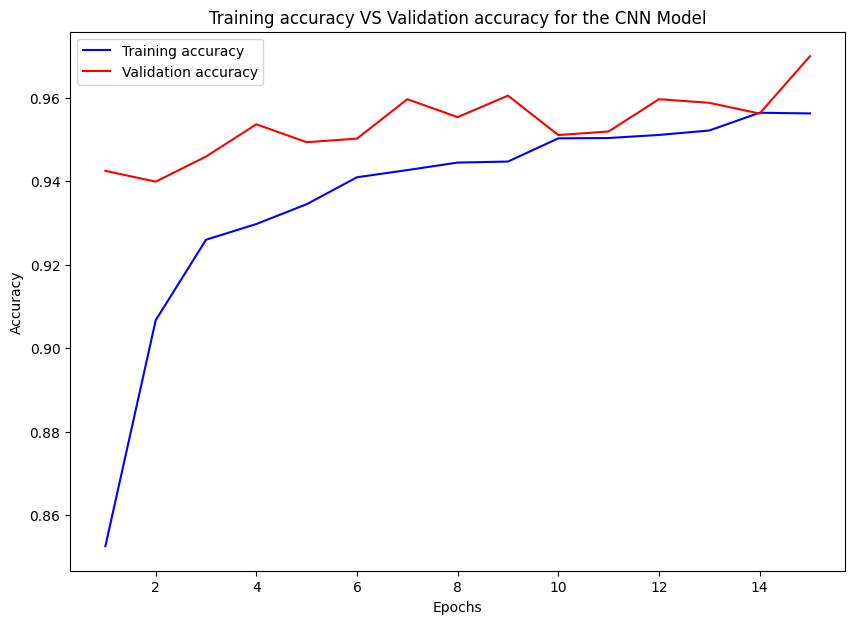

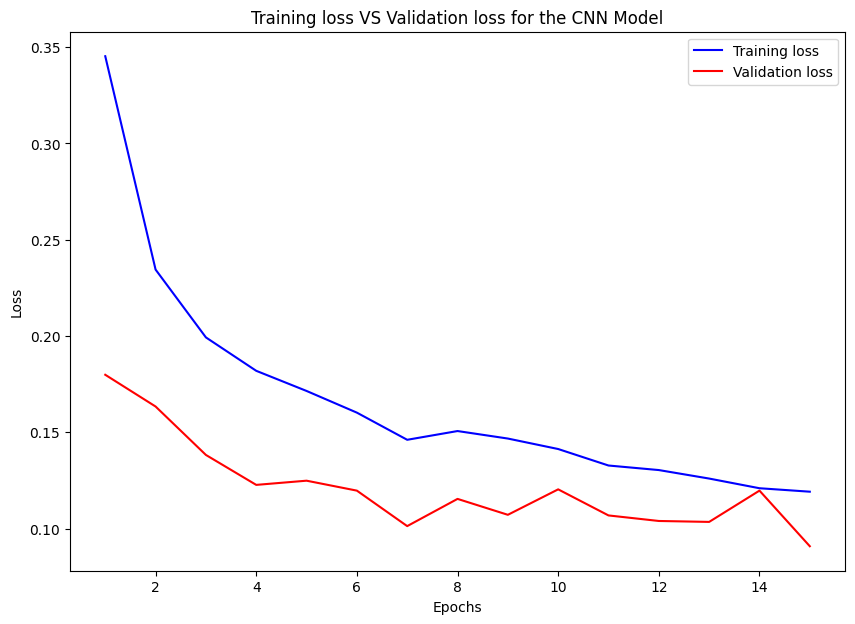

In [36]:
generated_model.summary(0)
plt.figure(figsize=(10, 7))
plt.plot(range(1, len(generated_model_history.history['accuracy']) + 1), generated_model_history.history['accuracy'], color="blue", label="Training accuracy", linestyle="-")
plt.plot(range(1, len(generated_model_history.history['val_accuracy']) + 1), generated_model_history.history['val_accuracy'], color="red", label="Validation accuracy", linestyle="-")
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title("Training accuracy VS Validation accuracy for the CNN Model")
plt.legend()
plt.show()

plt.figure(figsize=(10, 7))
plt.plot(range(1, len(generated_model_history.history['loss']) + 1), generated_model_history.history['loss'], color="blue", label="Training loss", linestyle="-")
plt.plot(range(1, len(generated_model_history.history['val_loss']) + 1), generated_model_history.history['val_loss'], color="red", label="Validation loss", linestyle="-")
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title("Training loss VS Validation loss for the CNN Model")
plt.legend()
plt.show()



---
### CNN Model Training Results

The following results show the progression of the CNN model training over 12 epochs. 

- **Accuracy**: The model's ability to correctly classify images. It started with a **training accuracy of 85.26%** and improved to **95.63%** by the final epoch, indicating that the model is learning effectively.

- **Loss**: The measure of how well the model's predictions match the true labels. Initially, the loss was **0.3453**, and by the last epoch, it decreased to **0.1304**, showing a reduction in error.

The model's performance improved consistently , demonstrating its ability to generalize well and avoid overfitting.

---


#  5:Simple CNN Model 

In this step, we build a simpler version of the Convolutional Neural Network (CNN)to compare its performance with the more complex model. 

The architecture includes:
- 1 Conv2D layer with 32 filters and ReLU activation.
- AveragePooling2D layer for downsampling.
- Flatten layer to convert 2D data into 1D.
- 1 Dense layer with 64 neurons and ReLU activation.
- Dropout layer with a rate of 0.3 to prevent overfitting.
- Final output layer with sigmoid activation for binary classification (Pneumonia vs. Normal).



In [30]:

model_simple = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(IMG_SIZE[0], IMG_SIZE[1],3)),
    AveragePooling2D(2,2),
    Flatten(),
    Dense(64, activation='relu'),
    Dropout(0.3), 
    Dense(1, activation='sigmoid')
])

model_simple.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
history_simple = model_simple.fit(train_img_loader, validation_data=val_img_loader, epochs=15)

Epoch 1/15
765/765 ━━━━━━━━━━━━━━━━━━━━ 103s 133ms/step - accuracy: 0.8163 - loss: 0.4180 - val_accuracy: 0.8292 - val_loss: 0.3691
Epoch 2/15
765/765 ━━━━━━━━━━━━━━━━━━━━ 100s 131ms/step - accuracy: 0.8733 - loss: 0.2948 - val_accuracy: 0.9193 - val_loss: 0.1954
Epoch 3/15
765/765 ━━━━━━━━━━━━━━━━━━━━ 103s 134ms/step - accuracy: 0.8943 - loss: 0.2588 - val_accuracy: 0.9288 - val_loss: 0.1863
Epoch 4/15
765/765 ━━━━━━━━━━━━━━━━━━━━ 99s 130ms/step - accuracy: 0.9024 - loss: 0.2452 - val_accuracy: 0.9425 - val_loss: 0.1551
Epoch 5/15
765/765 ━━━━━━━━━━━━━━━━━━━━ 100s 131ms/step - accuracy: 0.9100 - loss: 0.2318 - val_accuracy: 0.9399 - val_loss: 0.1758
Epoch 6/15
765/765 ━━━━━━━━━━━━━━━━━━━━ 98s 128ms/step - accuracy: 0.9139 - loss: 0.2217 - val_accuracy: 0.9425 - val_loss: 0.1474
Epoch 7/15
765/765 ━━━━━━━━━━━━━━━━━━━━ 143s 187ms/step - accuracy: 0.9145 - loss: 0.2162 - val_accuracy: 0.9502 - val_loss: 0.1447
Epoch 8/15
765/765 ━━━━━━━━━━━━━━━━━━━━ 151s 197ms/step - accuracy: 0.9201 - l

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_18 (Conv2D)              │ (None, 118, 118, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 59, 59, 32)     │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 111392)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 64)             │     7,129,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,390,341 (81.60 MB)

 Trainable params: 7,130,113 (27.20 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 14,260,228 (54.40 MB)

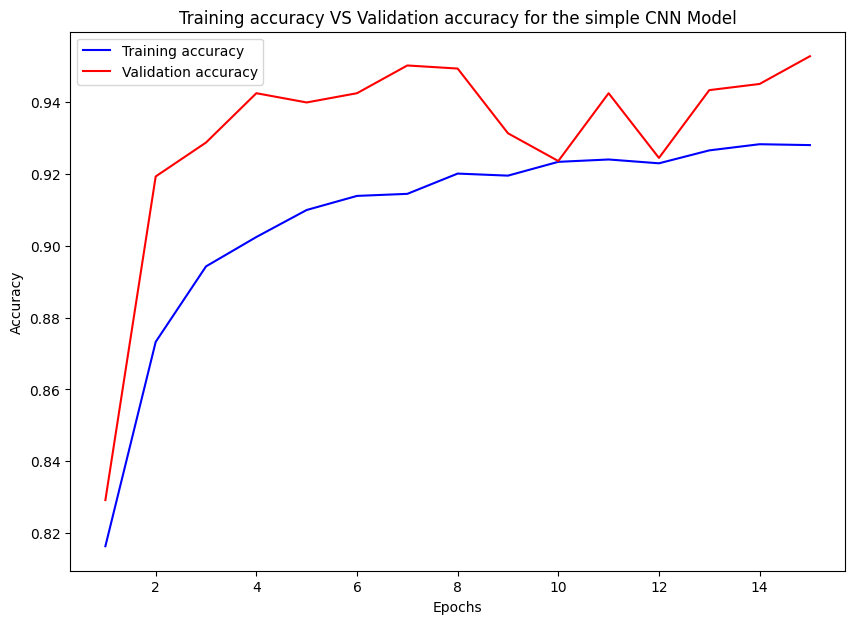

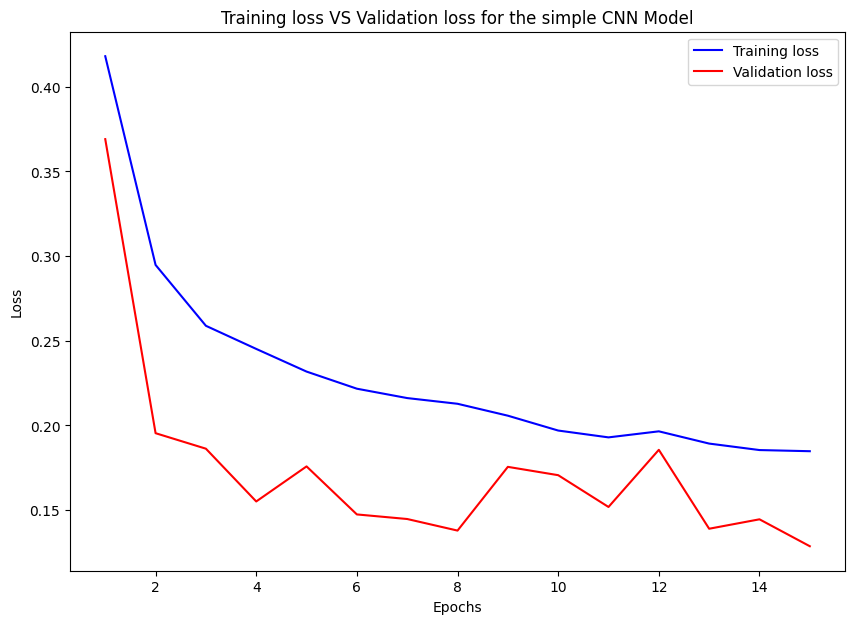

In [40]:
model_simple.summary(0)
plt.figure(figsize=(10, 7))
plt.plot(range(1, len(history_simple.history['accuracy']) + 1), history_simple.history['accuracy'], color="blue", label="Training accuracy", linestyle="-")
plt.plot(range(1, len(history_simple.history['val_accuracy']) + 1), history_simple.history['val_accuracy'], color="red", label="Validation accuracy", linestyle="-")
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title("Training accuracy VS Validation accuracy for the simple CNN Model")
plt.legend()
plt.show()

plt.figure(figsize=(10, 7))
plt.plot(range(1, len(history_simple.history['loss']) + 1), history_simple.history['loss'], color="blue", label="Training loss", linestyle="-")
plt.plot(range(1, len(history_simple.history['val_loss']) + 1), history_simple.history['val_loss'], color="red", label="Validation loss", linestyle="-")
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title("Training loss VS Validation loss for the simple CNN Model")
plt.legend()
plt.show()



CNN model shows steady improvement over 15 epochs. Both training and validation accuracy increase consistently, reaching around 0.95 for validation accuracy, with a corresponding decrease in loss. The model seems to have learned well, as it avoids overfitting despite the increasing validation loss at the very end of training.

Training Accuracy: 0.9563    loss: 0.1191  


Validation Accuracy: 0.9700   loss :0.0908  





The simple CNN model also shows significant progress, but the results are less stable than the first model. The training accuracy starts higher but fluctuates more significantly. Validation accuracy also peaks but sees some fluctuations, with a slight increase in loss during later epochs.

Training Accuracy: 0.9280   loss:0.1848  
 

Validation Accuracy: 0.9528  loss:0.1287 

--- 

The difference between the aforementioned models lies in their complexity. As previously discussed, the deep CNN architecture was capable of identifying more complex features from the images. Conversely, the simple CNN architecture was able to recognize fundamental features from images. Thus, it may be stated that the deep CNN architecture ensures more accuracy in image recognition tasks compared to the simple CNN architecture.

---


# **6: Comparison Between CNN Models**


1. **Model Complexity**:
   - The **complex model** uses **more layers** (3 Conv2D layers and MaxPooling), making it more capable of extracting features, while the **simple model** uses only **1 Conv2D layer** and **AveragePooling** for downsampling.
   
2. **Performance**:
   - The **complex model** achieved higher validation accuracy (**95.63%**) compared to the simple model (**92.80%**).
   - The **complex model** also performed better in terms of **loss**, reaching **0.1191**, whereas the simple model's final loss was **0.1848**.
   

   



In [48]:

def evaluate_model(model, test_img_loader):
    test_img_loader.reset()
    preds = model.predict(test_img_loader)
    preds_classes = (preds > 0.5).astype(int)
    y_true = test_img_loader.classes

    acc = accuracy_score(y_true, preds_classes)
    prec = precision_score(y_true, preds_classes)
    rec = recall_score(y_true, preds_classes)
    f1 = f1_score(y_true, preds_classes)
    cm = confusion_matrix(y_true, preds_classes)
    
    return acc, prec, rec, f1, cm

acc1, prec1, rec1, f1_1, cm1 = evaluate_model(generated_model, test_img_loader)
print("CNN Model Metrics:")
print(f"Accuracy: {acc1}, Precision: {prec1}, Recall: {rec1}, F1-score: {f1_1}")


acc2, prec2, rec2, f1_2, cm2 = evaluate_model(model_simple, test_img_loader)
print("\nSimple CNN Model Metrics:")
print(f"Accuracy: {acc2}, Precision: {prec2}, Recall: {rec2}, F1-score: {f1_2}")







582/582 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step
CNN Model Metrics:
Accuracy: 0.9587628865979382, Precision: 0.9731051344743277, Recall: 0.9683698296836983, F1-score: 0.9707317073170731
582/582 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step

Simple CNN Model Metrics:
Accuracy: 0.936426116838488, Precision: 0.9495192307692307, Recall: 0.9610705596107056, F1-score: 0.9552599758162031


* ### Deep CNN Model Metrics:
  The CNN model achieved a high overall performance in classifying Normal and Pneumonia cases. It reached an accuracy of 95.88%, indicating that the vast majority of predictions were correct. The model’s precision is 97.31%, showing that most of the cases predicted as Pneumonia were truly Pneumonia. Its recall is 96.84%, meaning it successfully detected nearly all actual Pneumonia cases. The F1-score of 97.07% demonstrates a strong balance between precision and recall, confirming the model’s reliability in medical diagnostics.


* ### Simple CNN Model Metrics:
  The simple CNN model also performed well, with an accuracy of 93.64%, slightly lower than the more complex CNN. Its precision is 94.95%, and recall is 96.11%, indicating it effectively identifies Pneumonia cases while maintaining relatively few false positives. The F1-score of 95.53% reflects a good trade-off between precision and recall, making this simpler model a reliable alternative when computational resources are limited.

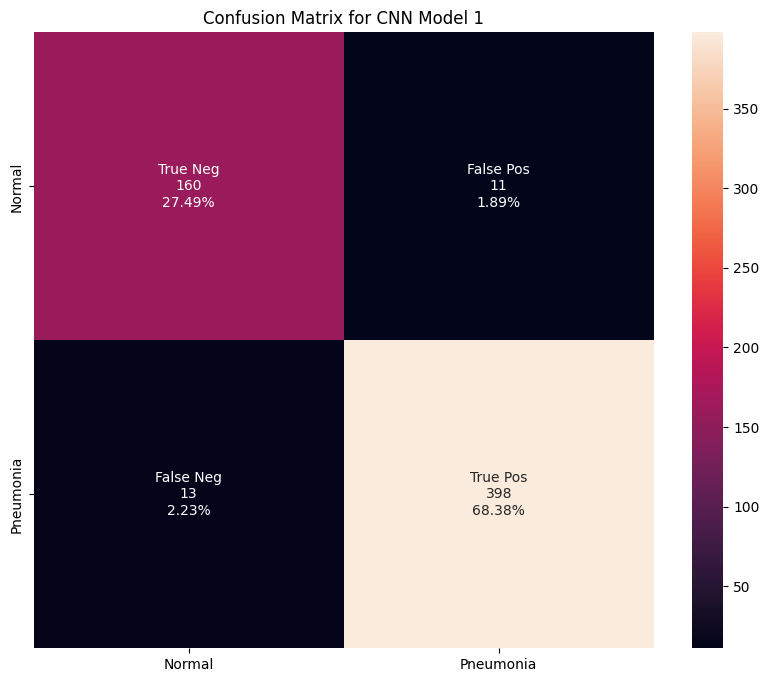

True Negative (TN): 160
False Positive (FP): 11
False Negative (FN): 13
True Positive (TP): 398


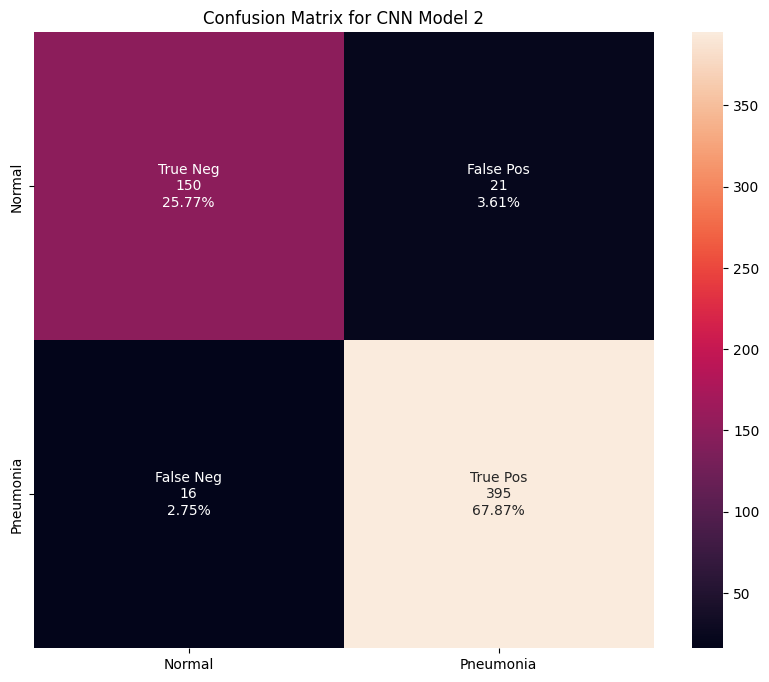

True Negative (TN): 150
False Positive (FP): 21
False Negative (FN): 16
True Positive (TP): 395


In [ ]:
import seaborn as sns

def plot_confusion_matrix(cm, model_name):
    group_names = ['True Neg', 'False Pos', 'False Neg', 'True Pos']
    group_counts = ['{0:0.0f}'.format(value) for value in cm.flatten()]
    group_percentages = ['{0:.2%}'.format(value) for value in cm.flatten() / np.sum(cm)]
    labels = [f'{v1}\n{v2}\n{v3}' for v1, v2, v3 in zip(group_names, group_counts, group_percentages)]
    labels = np.asarray(labels).reshape(2, 2)

    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=labels, fmt='', xticklabels=['Normal', 'Pneumonia'], yticklabels=['Normal', 'Pneumonia'])
    plt.title(f'Confusion Matrix for {model_name}')
    plt.show()

plot_confusion_matrix(cm1, 'CNN Model 1')
print("True Negative (TN):", cm1[0][0])
print("False Positive (FP):", cm1[0][1])
print("False Negative (FN):", cm1[1][0])
print("True Positive (TP):", cm1[1][1])
plot_confusion_matrix(cm2, 'CNN Model 2')
print("True Negative (TN):", cm2[0][0])
print("False Positive (FP):", cm2[0][1])
print("False Negative (FN):", cm2[1][0])
print("True Positive (TP):", cm2[1][1])


The confusion matrix of the deep CNN model shows its performance in classifying between Normal and Pneumonia cases. The model achieved 160 true negatives (27.49%), correctly identifying Normal images, and 398 true positives (68.38%), correctly detecting Pneumonia cases. There were 11 false positives (1.89%), where Normal images were incorrectly classified as Pneumonia, and 13 false negatives (2.23%), where Pneumonia cases were missed and classified as Normal. Overall, the model demonstrates high accuracy, particularly in detecting Pneumonia cases, with a very low false negative rate. This is especially important in medical applications, as minimizing missed cases is critical. In conclusion, the model is reliable and performs well in distinguishing between healthy and diseased lungs.

The confusion matrix for the simple CNN model demonstrates its ability to classify Normal and Pneumonia cases. The model correctly identified 150 Normal images (25.77%) as true negatives and 395 Pneumonia cases (67.87%) as true positives. There were 21 false positives (3.61%), where Normal images were incorrectly classified as Pneumonia, and 16 false negatives (2.75%), where Pneumonia cases were missed and classified as Normal. Overall, the model shows good performance with a relatively low false negative rate, which is crucial in medical diagnostics to minimize missed Pneumonia cases. Although slightly less accurate than more complex models, this simple CNN is still reliable for distinguishing between healthy and diseased lungs.